## Step 1 - Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

## Step 2 - Load and Inspect the Data

In [2]:
df = pd.read_csv('CC_Customer_Dataset.csv')
df.head()

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


Terdapat 660 data tanpa *missing value*. Kolom `Sl_No` dan `Customer Key` hanya berupa nomor urut / ID pelanggan, sehingga **bukan fitur yang bisa dipakai** untuk clustering. Fitur yang dipakai: `Avg_Credit_Limit`, `Total_Credit_Cards`, `Total_visits_bank`, `Total_visits_online`, `Total_calls_made`.

*(Catatan: nama kolom di dataset adalah `Total_Credit_Cards`, dengan huruf C kapital.)*

## Soal 1 - Scatter plot `Avg_Credit_Limit` vs `Total_Credit_Cards`

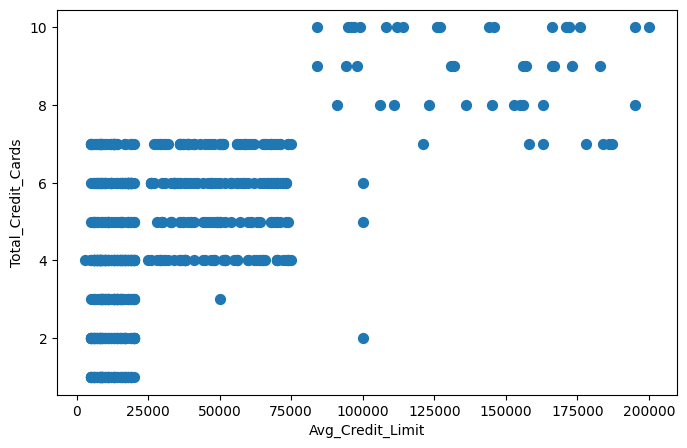

Korelasi Pearson: 0.6088604935524955


In [4]:
X = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]

plt.figure(figsize=(8, 5))
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=50)
plt.show()

print('Korelasi Pearson:', X.corr().iloc[0, 1])

**Apakah distribusi data dapat dianggap linear?**

Tidak. Memang ada tren positif (korelasi Pearson sekitar 0,61): semakin besar limit kredit, cenderung semakin banyak kartu kredit. Namun titik-titik tidak membentuk pola garis lurus, melainkan **berkelompok seperti blok/tangga**:

- limit rendah (di bawah sekitar 20.000) dengan 1-4 kartu,
- limit menengah (sekitar 20.000-75.000) dengan 4-7 kartu,
- limit tinggi (di atas sekitar 85.000) dengan 7-10 kartu.

Karena `Total_Credit_Cards` bernilai bilangan bulat dan data terkumpul dalam kelompok-kelompok, sebaran ini lebih cocok dianggap sebagai **kelompok (cluster)** daripada hubungan linear. Itulah alasan clustering cocok dipakai di sini.

## Soal 2 - K-Means dan penentuan k dengan Elbow Method

Skala kedua variabel sangat berbeda (limit kredit sampai 200.000, jumlah kartu hanya 1-10). Karena K-Means berbasis jarak, limit kredit akan mendominasi. Maka data **distandarisasi** terlebih dahulu dengan `StandardScaler` (seperti di JS02).

In [5]:
scaler2 = StandardScaler()
X_scaled = scaler2.fit_transform(X)

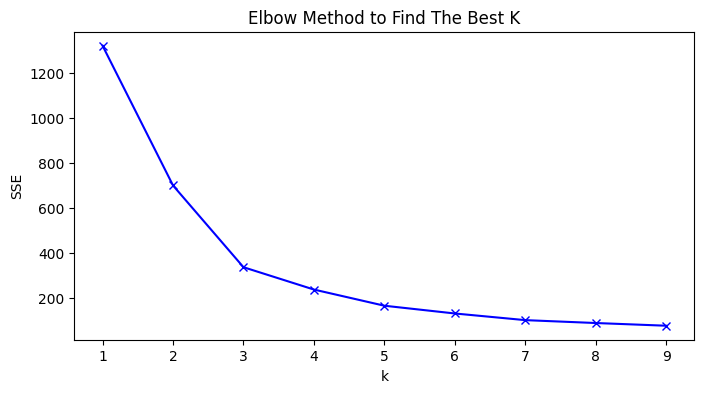

k=1: SSE=1320.00
k=2: SSE=698.29
k=3: SSE=334.72
k=4: SSE=235.39
k=5: SSE=163.47
k=6: SSE=128.96
k=7: SSE=99.37
k=8: SSE=86.53
k=9: SSE=74.53


In [6]:
# Find the best k using Elbow Method
sse = []
K = range(1, 10)

for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeanModel.fit(X_scaled)
    sse.append(kmeanModel.inertia_)   # harus di dalam loop

# Plotting
plt.figure(figsize=(8, 4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Elbow Method to Find The Best K")
plt.show()

for k, s in zip(K, sse):
    print(f'k={k}: SSE={s:.2f}')

**Alasan memilih k = 3**

SSE turun sangat tajam dari k=1 (sekitar 1320) ke k=2 (sekitar 698) dan ke k=3 (sekitar 335). Setelah k=3, penurunannya jauh lebih landai (k=4 sekitar 235, k=5 sekitar 164, dan seterusnya). Titik tempat penurunan tajam berhenti dan berganti menjadi landai itulah "siku" (*elbow*), yaitu **k = 3**.

SSE pasti terus turun saat k bertambah karena tiap cluster makin kecil dan makin rapat, jadi SSE kecil saja tidak berarti k itu ideal. Yang dicari adalah k terakhir yang masih memberi penurunan signifikan. Pilihan k=3 juga sesuai dengan scatter plot Soal 1 yang memperlihatkan tiga kelompok (limit rendah, menengah, tinggi).

## Soal 3 - Visualisasi hasil K-Means (k = 3)

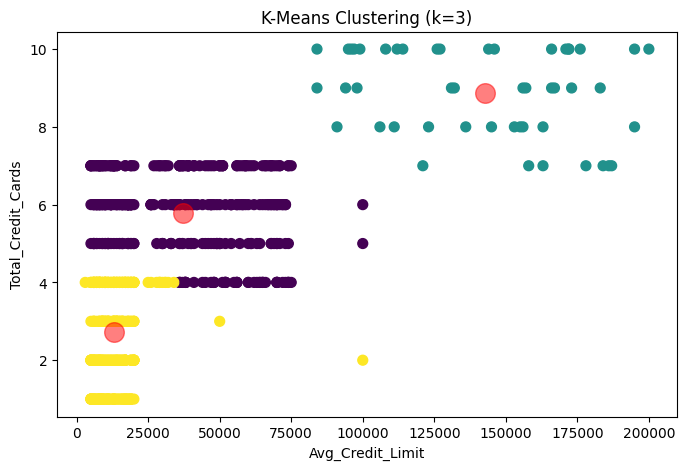

Jumlah anggota tiap cluster: [330  48 282]
Centroid (Avg_Credit_Limit, Total_Credit_Cards):
[[3.71606e+04 5.80000e+00]
 [1.42750e+05 8.90000e+00]
 [1.31348e+04 2.70000e+00]]


In [7]:
cl_kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
y_kmeans = cl_kmeans.fit_predict(X_scaled)

# Plot hasil cluster (sumbu dalam satuan asli)
plt.figure(figsize=(8, 5))
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s=50, c=y_kmeans)

# Plot centroid (dikembalikan ke skala asli)
centers = scaler2.inverse_transform(cl_kmeans.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('K-Means Clustering (k=3)')
plt.show()

print('Jumlah anggota tiap cluster:', np.bincount(y_kmeans))
print('Centroid (Avg_Credit_Limit, Total_Credit_Cards):')
print(centers.round(1))

Tiga cluster yang terbentuk:

- **Cluster limit tinggi**: limit rata-rata sekitar 142.750 dengan sekitar 9 kartu (48 pelanggan).
- **Cluster limit menengah**: limit rata-rata sekitar 37.160 dengan sekitar 6 kartu (330 pelanggan).
- **Cluster limit rendah**: limit rata-rata sekitar 13.135 dengan sekitar 3 kartu (282 pelanggan).

*(Urutan label 0/1/2 pada warna bisa berbeda di komputer Anda, tetapi pembagian kelompoknya sama.)*

## Soal 4 - DBSCAN dengan semua variabel yang dapat dipakai

In [8]:
# Pilih semua fitur yang usable: buang Sl_No dan Customer Key (hanya ID)
X_all = df[['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
            'Total_visits_online', 'Total_calls_made']]

# Standardisasi
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

X_all.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


`Sl_No` dan `Customer Key` dibuang karena hanya penomoran/identitas pelanggan dan tidak mengandung informasi perilaku. Data distandarisasi karena DBSCAN juga berbasis jarak (parameter `eps` sangat bergantung pada skala data).

## Soal 5 - Menentukan parameter dengan Elbow Method (k-distance plot)

Pada DBSCAN tidak ada parameter jumlah cluster k. Sesuai materi DBSCAN, parameter `eps` dicari dengan heuristik mencari "siku" pada **grafik jarak ke tetangga terdekat** (*nearest-neighbor distance plot*). Kita tetapkan `min_samples = 6` (jumlah fitur + 1), lalu urutkan jarak tiap titik ke tetangga ke-6 terdekatnya.

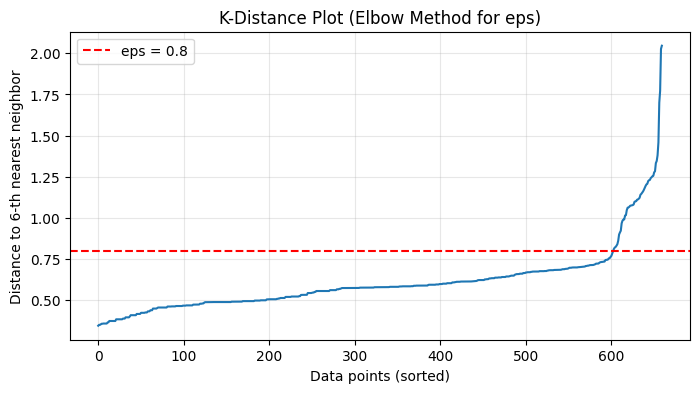

In [9]:
min_samples = 6

nn = NearestNeighbors(n_neighbors=min_samples)
nn.fit(X_all_scaled)
distances, indices = nn.kneighbors(X_all_scaled)

# jarak ke tetangga ke-min_samples, diurutkan
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.axhline(y=0.8, color='r', linestyle='--', label='eps = 0.8')
plt.xlabel('Data points (sorted)')
plt.ylabel(f'Distance to {min_samples}-th nearest neighbor')
plt.title('K-Distance Plot (Elbow Method for eps)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Alasan memilih eps = 0,8**

Pada grafik, jarak naik sangat landai untuk sebagian besar titik (sampai sekitar 0,75), lalu melonjak tajam. Titik belok (siku) berada di sekitar **0,75-0,8**. Titik di sebelah kiri siku berada di area padat (calon anggota cluster), sedangkan titik di kanan siku berada di area jarang (calon *noise*/outlier).

Sesuai materi: bila `eps` terlalu kecil, kebanyakan data menjadi noise (-1); bila terlalu besar, cluster-cluster menyatu. Maka dipilih **eps = 0,8** dan **min_samples = 6**.

In [10]:
dbscan = DBSCAN(eps=0.8, min_samples=6)
cluster_db = dbscan.fit_predict(X_all_scaled)

labels, counts = np.unique(cluster_db, return_counts=True)
for l, c in zip(labels, counts):
    print(f'Label {l:>2}: {c} data')

n_clusters = len(set(cluster_db)) - (1 if -1 in cluster_db else 0)
n_noise = (cluster_db == -1).sum()
print(f'Jumlah cluster: {n_clusters}')
print(f'Jumlah noise  : {n_noise} ({n_noise / len(cluster_db) * 100:.1f}%)')

Label -1: 48 data
Label  0: 606 data
Label  1: 6 data
Jumlah cluster: 2
Jumlah noise  : 48 (7.3%)


## Soal 6 - Silhouette Score dan DBI pada model DBSCAN

In [11]:
# Seluruh data (noise = label -1 ikut dihitung), seperti di Lab 2
sil = silhouette_score(X_all_scaled, cluster_db)
dbi = davies_bouldin_score(X_all_scaled, cluster_db)
print(f'Silhouette Score          : {sil}')
print(f'Davies-Bouldin Index (DBI): {dbi}')

# Pembanding: tanpa titik noise
mask = cluster_db != -1
sil_nn = silhouette_score(X_all_scaled[mask], cluster_db[mask])
dbi_nn = davies_bouldin_score(X_all_scaled[mask], cluster_db[mask])
print()
print('Tanpa noise:')
print(f'Silhouette Score          : {sil_nn}')
print(f'Davies-Bouldin Index (DBI): {dbi_nn}')

Silhouette Score          : 0.47249305242066064
Davies-Bouldin Index (DBI): 2.2742170090628684

Tanpa noise:
Silhouette Score          : 0.531451361617916
Davies-Bouldin Index (DBI): 0.4946672417743444


**Analisis**

| Perhitungan | Silhouette Score | DBI |
|---|---|---|
| Seluruh data (noise ikut dihitung) | sekitar 0,472 | sekitar 2,274 |
| Tanpa titik noise | sekitar 0,531 | sekitar 0,495 |

- Silhouette sekitar 0,47-0,53 menunjukkan struktur cluster yang cukup wajar, tetapi tidak sangat kuat.
- DBI kecil lebih baik. Nilai 2,27 (noise ikut dihitung) buruk karena noise dianggap satu "cluster" yang menyebar luas; tanpa noise DBI turun menjadi sekitar 0,49 yang tergolong baik.
- DBSCAN dengan 5 variabel hanya menemukan **satu cluster besar (606 data)**, satu cluster sangat kecil (6 data), dan 48 data noise (sekitar 7,3%). Artinya pelanggan pada dataset ini tidak terpisah oleh area kosong yang jelas pada ruang 5 dimensi; kepadatannya relatif merata, sehingga DBSCAN cenderung menggabungkannya. Ini menunjukkan K-Means (k=3) memberi segmentasi yang lebih bermakna untuk data ini, sedangkan DBSCAN lebih berguna untuk mendeteksi pelanggan yang tidak biasa (outlier).